In [1]:
# Loading the dataset!

import pandas as pd
import numpy as np

df = pd.read_csv('Housing.csv')
print("Shape :", df.shape)
df.head(6)

Shape : (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [3]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [4]:
# Converting text to numbers using map()!

yes_no_cols = ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']

for col in yes_no_cols:
    df[col] = df[col].map({'yes':1,'no' : 0})

df[yes_no_cols].head()    

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea
0,1,0,0,0,1,1
1,1,0,0,0,1,0
2,1,0,1,0,0,1
3,1,0,1,0,1,1
4,1,1,1,0,1,0


In [5]:
# Checking if encoded are not becuase of error!!
df.info()

df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    int64 
 6   guestroom         545 non-null    int64 
 7   basement          545 non-null    int64 
 8   hotwaterheating   545 non-null    int64 
 9   airconditioning   545 non-null    int64 
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    int64 
 12  furnishingstatus  545 non-null    object
dtypes: int64(12), object(1)
memory usage: 55.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column                           Non-Null C

In [6]:
# Seperating target and features!

X = df.drop('price', axis = 1)
y = df['price']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (545, 13)
Target shape: (545,)


In [7]:
# Splitting from traing and testing!

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print("Training state:", X_train.shape)
print("Testing state:", X_test.shape)

Training state: (436, 13)
Testing state: (109, 13)


In [8]:
# Model Training

from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train,y_train)
print("Model Trained!")

Model Trained!


In [9]:
# Checking Datatype!

X_train.dtypes

area                               int64
bedrooms                           int64
bathrooms                          int64
stories                            int64
mainroad                           int64
guestroom                          int64
basement                           int64
hotwaterheating                    int64
airconditioning                    int64
parking                            int64
prefarea                           int64
furnishingstatus_semi-furnished     bool
furnishingstatus_unfurnished        bool
dtype: object

In [10]:
from sklearn.metrics import r2_score,mean_absolute_error

y_pred = model.predict(X_test)
r2 = r2_score(y_test , y_pred)
mae = mean_absolute_error(y_test , y_pred)

print("R² Score:", r2)
print("Mean absolute error:", round(mae,3))

R² Score: 0.6529242642153186
Mean absolute error: 970043.404


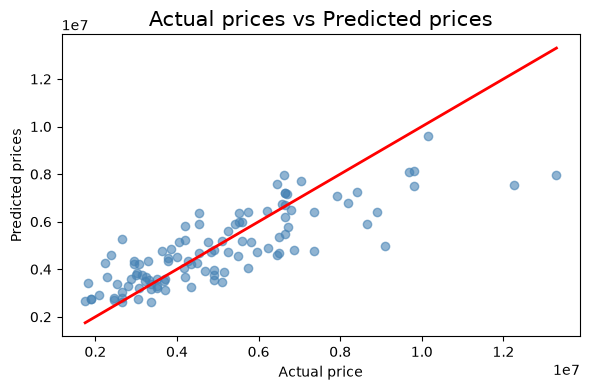

In [11]:
y_pred = model.predict(X_test)

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(y_test , y_pred, color = 'steelblue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color = 'red', linewidth = 2)
plt.title("Actual prices vs Predicted prices" , fontsize = 15)
plt.xlabel("Actual price")
plt.ylabel("Predicted prices")
plt.tight_layout()
plt.show()

In [12]:
df.to_csv('housing_encoded.csv', index=False)

## Summary — House Price Prediction

Built a Linear Regression model to predict house prices using features like 
area, bedrooms, bathrooms, stories, parking, and amenities (mainroad, 
guestroom, basement, hot water heating, air conditioning, preferred area, 
and furnishing status).

## Data Preparation
- Dataset: 545 rows, 13 columns, no missing values
- Encoded 6 yes/no columns using `.map()`
- One-hot encoded `furnishingstatus` (3 categories) using `pd.get_dummies()`

## Model Performance
- **R² Score: 0.65** — model explains 65% of price variation.
- **Mean Absolute Error: ₹9.7 lakhs** — average prediction error

## Key Finding
The model performs well for mid-range houses like in range (₹20L-₹80L) but tends to 
under-predict for high-value properties or houses (₹1 crore+). This is likely because 
the dataset has fewer examples/records of expensive houses, and features like exact 
location, brand value, or premium amenities aren't captured in this dataset — 
which would matter more for luxury properties.

### Tools Used
- Python, Pandas, NumPy
- Scikit-learn (LinearRegression, train_test_split, r2_score, mean_absolute_error)
- Matplotlib.